In [1]:
from pathlib import Path
import os

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

os.chdir(project_root)

print("Current working directory:")
print(os.getcwd())

Current working directory:
/home/anshul/crop-disease-detection


In [2]:
import json
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("TensorFlow version:", tf.__version__)

I0000 00:00:1795635020.602558    5996 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795635021.061808    5996 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795635022.588459    5996 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


In [3]:
model = keras.models.load_model("models/best_resnet50_model.keras")

print("Best ResNet50 model loaded successfully.")
model.summary()

I0000 00:00:1795635027.987615    5996 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4135 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Best ResNet50 model loaded successfully.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,190,644 (96.09 MB)

 Trainable params: 534,310 (2.04 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 1,068,622 (4.08 MB)

In [4]:
valid_data = tf.keras.utils.image_dataset_from_directory(
    "data/valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = valid_data.class_names

AUTOTUNE = tf.data.AUTOTUNE

def prepare_batch(images, labels):
    images = preprocess_input(images)
    return images, labels

valid_data = valid_data.map(
    prepare_batch,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Number of classes:", len(class_names))
print("Validation data ready.")

Found 17572 files belonging to 38 classes.
Number of classes: 38
Validation data ready.


In [5]:
y_true = []
y_pred = []
y_pred_probs = []

for images, labels in valid_data:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))
    y_pred_probs.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_pred_probs = np.array(y_pred_probs)

print("True labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Prediction probabilities shape:", y_pred_probs.shape)

I0000 00:00:1795635096.885926    7314 service.cc:153] XLA service 0x7dead4065170 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795635096.885954    7314 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795635096.968561    7314 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795635097.654905    7314 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795635101.288215    7314 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795635106.658741    7314 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most

True labels shape: (17572,)
Predicted labels shape: (17572,)
Prediction probabilities shape: (17572, 38)


In [6]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted")
recall = recall_score(y_true, y_pred, average="weighted")
f1 = f1_score(y_true, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.9803095834281812
Precision: 0.980753996772635
Recall: 0.9803095834281812
F1-score: 0.9802793531116512


In [7]:
os.makedirs("results", exist_ok=True)

resnet_evaluation = {
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1)
}

with open("results/resnet50_evaluation.json", "w") as f:
    json.dump(resnet_evaluation, f, indent=4)

print("Evaluation results saved to results/resnet50_evaluation.json")
print(resnet_evaluation)

Evaluation results saved to results/resnet50_evaluation.json
{'accuracy': 0.9803095834281812, 'precision': 0.980753996772635, 'recall': 0.9803095834281812, 'f1_score': 0.9802793531116512}


In [8]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

with open("results/resnet50_classification_report.txt", "w") as f:
    f.write(report)

print("Classification report saved.")

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9748    0.9960    0.9853       504
                                 Apple___Black_rot     1.0000    0.9879    0.9939       497
                          Apple___Cedar_apple_rust     0.9865    0.9977    0.9921       440
                                   Apple___healthy     1.0000    0.9841    0.9920       502
                               Blueberry___healthy     1.0000    0.9824    0.9911       454
          Cherry_(including_sour)___Powdery_mildew     0.9976    1.0000    0.9988       421
                 Cherry_(including_sour)___healthy     0.9913    1.0000    0.9956       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9858    0.8463    0.9108       410
                       Corn_(maize)___Common_rust_     1.0000    0.9958    0.9979       477
               Corn_(maize)___Northern_Leaf_Blight     0.8804    0.9874    0.93

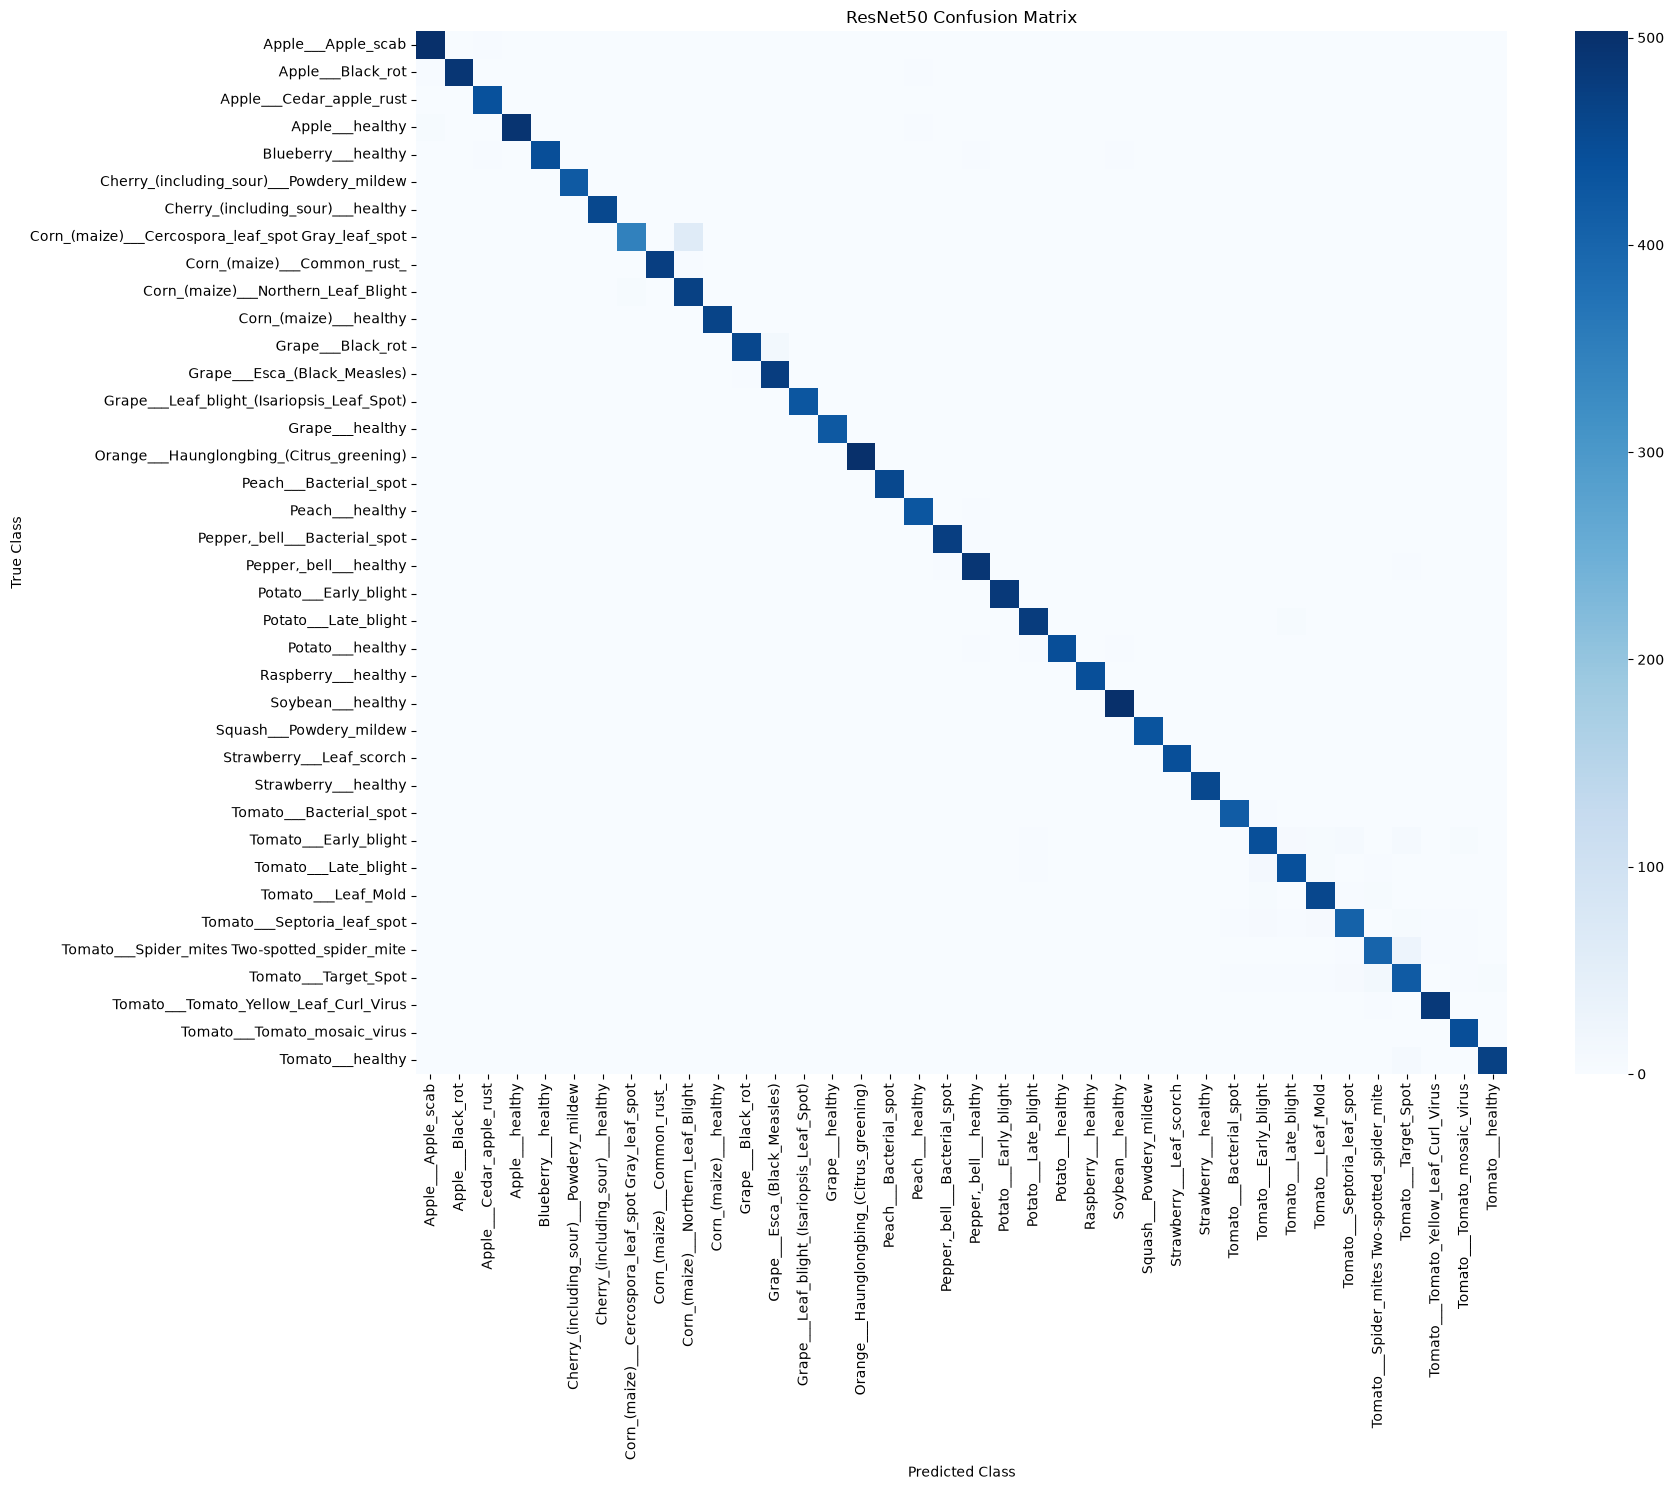

In [9]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

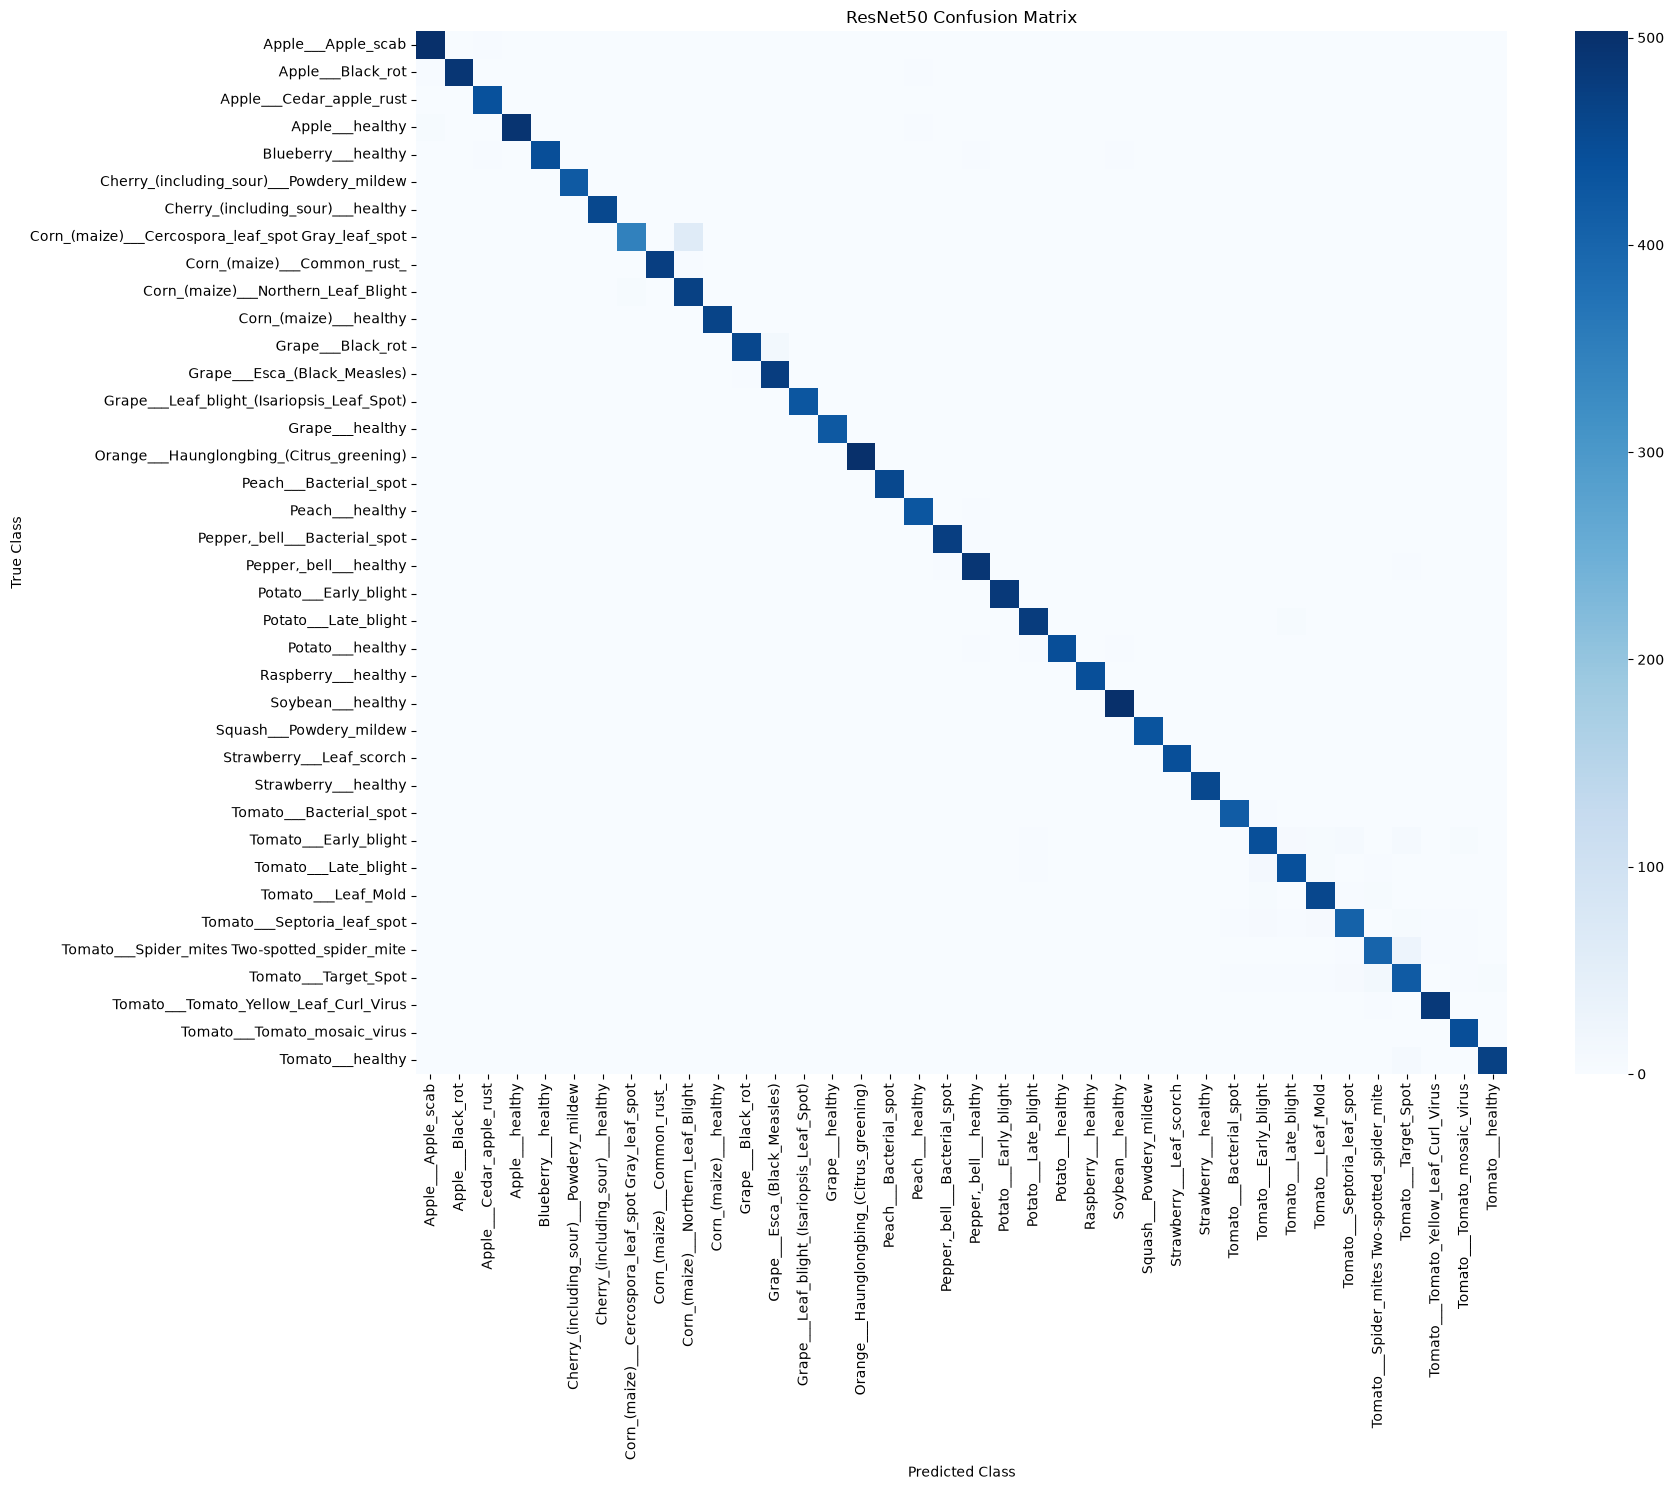

Confusion matrix saved to results/resnet50_confusion_matrix.png


In [10]:
plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("results/resnet50_confusion_matrix.png", dpi=300)
plt.show()

print("Confusion matrix saved to results/resnet50_confusion_matrix.png")